# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [15]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
-1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [16]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [17]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0             15             70  0.658543
1       1             12             62  0.665598
2       2             54            147  0.673914
3       3              9             54  0.672476
4       4            177            366  0.677893
5       5              4             43  0.659849
6       6             53            145  0.674191
7       7             -6              9  0.572307
8       8             32            104  0.672167

Best action: 4
230 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Some Tests

### x is about to win (play 8)

Board:


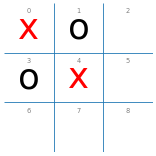


   action  total utility  # of playouts      UCB1
0       2             17             20  1.528614
1       5              8             12  1.542754
2       6             16             19  1.538349
3       7             14             18  1.493100
4       8             31             31  1.545076

Best action: 8
20.6 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [18]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

### o is about to win

Board:


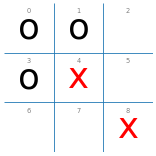


   action  total utility  # of playouts      UCB1
0       2             -1            547  0.157096
1       5            -10             10  0.175394
2       6              8            430  0.197851
3       7            -11             13  0.184735

Best action: 2
75.8 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [19]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### x can draw if it chooses 7

Board:


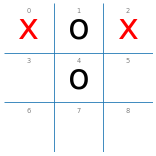


   action  total utility  # of playouts      UCB1
0       3            -12             23  0.253293
1       5            -10             88  0.282589
2       6            -12             47  0.286850
3       7            132            811  0.293281
4       8            -12             31  0.280482

Best action: 7
133 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [20]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### Empty board: Only a draw an be guaranteed

Board:


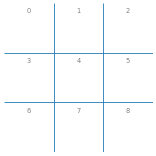


   action  total utility  # of playouts      UCB1
0       0             -1              7  1.004210
1       1             -2              4  1.017427
2       2              1             12  0.959420
3       3              0              9  1.011618
4       4              0             11  0.915043
5       5              3             15  0.983596
6       6             -2              6  0.905641
7       7             -1              7  1.004210
8       8             14             29  1.046317

Best action: 8
46.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
   action  total utility  # of playouts      UCB1
0       0             43            167  0.576863
1       1             55            196  0.575417
2       2            102            302  0.575246
3       3             48            180  0.574295
4       4           1748           3428  0.580411
5       5             12             90  0.568386
6       6             33            144  0.573106
7       7         

In [21]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

Khi tăng số lần mô phỏng từ 100 lên 5000, thuật toán UCT_depth1 có thêm dữ liệu để đánh giá các nước đi. 

Kết quả cho thấy nước đi được lựa chọn thay đổi từ ô 8 sang ô 4 (ô trung tâm), đồng thời số lượt mô phỏng tập trung nhiều hơn vào action 4. Tuy nhiên, thời gian thực hiện cũng tăng từ 46,1 ms lên 1,08 giây. Điều này thể hiện sự đánh đổi giữa chất lượng đánh giá và chi phí tính toán.

### A bad situation

Board:


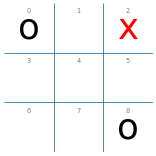


   action  total utility  # of playouts      UCB1
0       1             -4              6  0.572307
1       3             -4              6  0.572307
2       4             19             63  0.683943
3       5             -4              4  0.517427
4       6             -3             13  0.610948
5       7             -4              8  0.572983

Best action: 4


4

In [22]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [23]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [24]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 91, 'o': 5, 'd': 4}

552 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 15, 'o': 78, 'd': 7}

406 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [25]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 96, 'o': 1, 'd': 3}

4.51 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 6, 'o': 82, 'd': 12}

3.65 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [27]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 88, 'o': 0, 'd': 12}

6.61 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 34, 'o': 45, 'd': 21}

11.9 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét kết quả thực nghiệm:**

Qua các thử nghiệm, UCB1 thể hiện khả năng chơi tốt hơn Random trong cả hai vị trí X và O.

Khi tăng số lần mô phỏng từ 10 lên 100, kết quả thi đấu có xu hướng được cải thiện. Cụ thể, UCB1 (100) đạt kết quả tốt hơn UCB1 (10) khi đối đầu với Random cũng như khi hai phiên bản trực tiếp thi đấu với nhau.

Tuy nhiên, việc tăng số lần mô phỏng cũng làm thời gian tính toán tăng đáng kể. Chẳng hạn, thời gian chạy một trận UCB1 (100) vs Random là 4,51 giây khi UCB1 đi trước, so với 552 ms ở UCB1 (10).

Kết quả thực nghiệm cho thấy UCB1 có thể phân bổ ngân sách mô phỏng linh hoạt giữa các hành động thông qua hai thành phần Exploration và Exploitation. Số lần mô phỏng lớn hơn giúp thu thập nhiều thông tin hơn, nhưng cần đánh đổi bằng chi phí tính toán.

Ngoài ra, kết quả còn chịu ảnh hưởng của yếu tố ngẫu nhiên trong quá trình mô phỏng và lợi thế của người đi trước.

#### **Câu hỏi:**

**1. UCB1 cân bằng exploration và exploitation như thế nào?**

UCB1 cân bằng hai chiến lược thông qua công thức: \[
UCB1(a)=\frac{u(a)}{n(a)}
+C\sqrt{\frac{\ln N}{n(a)}}
\]

Trong đó, thành phần đầu tiên đại diện cho Exploitation, ưu tiên những nước đi có kết quả mô phỏng tốt. Thành phần thứ hai đại diện cho Exploration, khuyến khích thử nghiệm những nước đi có số lần mô phỏng thấp.

Nhờ kết hợp hai thành phần, thuật toán vừa khai thác thông tin đã thu thập được, vừa tiếp tục khám phá những lựa chọn chưa được đánh giá đầy đủ.

**2. Khi số lần mô phỏng tăng, quyết định có ổn định hơn không?**

Thông thường, khi số lần mô phỏng tăng, thuật toán thu thập được nhiều dữ liệu hơn về chất lượng của từng nước đi. Kết quả đánh giá ít bị ảnh hưởng bởi yếu tố ngẫu nhiên hơn, từ đó quyết định có xu hướng ổn định hơn.

Tuy nhiên, UCB1 vẫn sử dụng chính sách mô phỏng ngẫu nhiên nên kết quả không hoàn toàn cố định. Ngoài ra, số lần mô phỏng tăng cũng làm thời gian tính toán tăng lên.